# 5.2.2 · Delimitação espacial do Cerrado
## Dois mapas para a dissertação

**Mapa 1:** território brasileiro com o bioma Cerrado destacado.  
**Mapa 2:** ampliação do Cerrado, com limites estaduais, siglas das UFs e quadro com seus nomes.

**Como usar no Google Colab:** envie este `.ipynb` em **Arquivo → Fazer upload de notebook** e escolha **Ambiente de execução → Executar tudo**. As figuras aparecem abaixo das células e um ZIP é baixado ao final.

As saídas incluem PNG a 600 dpi, PDF vetorial, SVG editável, tabela de UFs e registro das fontes. Não é necessário carregar dados do SICOR.

### Escolha da delimitação
O padrão é a delimitação **IBGE 2019, escala de referência 1:250.000**, com malha estadual **IBGE 2024**. A versão de 2025 dos biomas também está disponível na configuração. **Para representar o recorte efetivamente utilizado na dissertação, use a mesma edição da delimitação empregada nos cruzamentos da pesquisa.** Se necessário, indique seu próprio arquivo na célula 2; nenhuma versão é substituída silenciosamente.

Fontes oficiais: [Biomas — arquivos vetoriais](https://geoftp.ibge.gov.br/informacoes_ambientais/estudos_ambientais/biomas/vetores/) e [Malhas territoriais 2024 — Brasil](https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2024/Brasil/).


## 1. Instalar bibliotecas
Execute esta célula uma vez por sessão. Não é necessária chave de API.

In [1]:
%pip -q install "geopandas>=1.0,<2" "shapely>=2.0,<3" "matplotlib>=3.8,<4" "pyproj>=3.6,<4" "requests>=2.31,<3"

## 2. Configuração
O download é automático quando os caminhos locais estão vazios. Para usar seus arquivos, envie-os pelo painel **Arquivos** do Colab e preencha o caminho. Aceita ZIP com Shapefile, SHP (com seus arquivos auxiliares), GeoPackage ou GeoJSON. Para GeoPackage com várias camadas, informe o nome da camada. Um arquivo próprio deve conter todos os biomas com coluna identificadora, ou somente o Cerrado.

`MOSTRAR_TITULO = False` gera figuras sem título interno, adequadas a legendas numeradas no Word. Os nomes de arquivo não fixam a numeração da dissertação.

In [2]:
from pathlib import Path
EDICAO_BIOMAS = "2019"              # "2019" ou "2025"
ARQUIVO_BIOMAS = ""                # Ex.: "/content/meu_cerrado.zip"
CAMADA_BIOMAS = None               # Nome de camada de um GeoPackage, se necessário
ARQUIVO_UFS = ""                   # Vazio = malha oficial IBGE 2024
CAMADA_UFS = None
ARQUIVO_CONTEM_SO_CERRADO = False   # True SOMENTE se o arquivo próprio contiver apenas o Cerrado
FONTE_BIOMAS_LOCAL = ""            # Preencha instituição, edição e escala se usar arquivo próprio
FONTE_UFS_LOCAL = ""               # Preencha instituição e edição se usar arquivo próprio
MOSTRAR_TITULO = True
DPI = 600
BAIXAR_ZIP_NO_COLAB = True
RAIZ = Path("/content/mapas_cerrado") if Path("/content").exists() else Path.cwd() / "mapas_cerrado"
DADOS, SAIDA = RAIZ / "dados", RAIZ / "figuras"
for pasta in (DADOS, SAIDA):
    pasta.mkdir(parents=True, exist_ok=True)
print("Pasta de saída:", SAIDA)


Pasta de saída: /content/mapas_cerrado/figuras


## 3. Obter as bases oficiais
Arquivos já baixados são reutilizados. Falhas de rede produzem uma orientação para envio manual; não há troca automática por outra base.

In [3]:
import hashlib, json, zipfile, unicodedata, platform
from datetime import datetime, timezone
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import Patch, Rectangle
from matplotlib.lines import Line2D
from pyproj import CRS, Transformer, Geod
from shapely.geometry import Point, Polygon, MultiPolygon, GeometryCollection, box

URL_BASE = "https://geoftp.ibge.gov.br/informacoes_ambientais/estudos_ambientais/biomas/vetores/"
URLS_BIOMAS = {
    "2019": URL_BASE + "Biomas_250mil.zip",
    "2025": URL_BASE + "2025_Biomas-e-Sistema-Costeiro-Marinho-do-Brasil-1-250000_shp.zip",
}
URL_UFS = "https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2024/Brasil/BR_UF_2024.zip"
assert EDICAO_BIOMAS in URLS_BIOMAS, "Escolha a edição 2019 ou 2025."

sessao = requests.Session()
sessao.mount("https://", HTTPAdapter(max_retries=Retry(total=3, backoff_factor=1, status_forcelist=[429,500,502,503,504])))
def obter(local, url, nome):
    if local:
        p = Path(local)
        if not p.is_file():
            raise FileNotFoundError(f"Arquivo não encontrado: {p}. Envie o arquivo pelo painel Arquivos.")
        return p
    p = DADOS / nome
    if p.exists() and zipfile.is_zipfile(p):
        print("Reutilizando:", p.name)
        return p
    tmp = p.with_suffix(".part")
    try:
        with sessao.get(url, stream=True, timeout=(30,180)) as resposta:
            resposta.raise_for_status()
            with tmp.open("wb") as f:
                for bloco in resposta.iter_content(1024*1024):
                    f.write(bloco)
        if not zipfile.is_zipfile(tmp):
            raise ValueError("O servidor não retornou um ZIP válido.")
        tmp.replace(p)
    except Exception as exc:
        tmp.unlink(missing_ok=True)
        raise RuntimeError(f"Falha no download de {url}. Baixe o ZIP pelo navegador, envie ao Colab e preencha o caminho na célula 2.") from exc
    print("Baixado:", p.name)
    return p

if ARQUIVO_BIOMAS and not FONTE_BIOMAS_LOCAL.strip():
    raise ValueError("Preencha FONTE_BIOMAS_LOCAL para registrar a origem do seu arquivo.")
if ARQUIVO_UFS and not FONTE_UFS_LOCAL.strip():
    raise ValueError("Preencha FONTE_UFS_LOCAL para registrar a origem do seu arquivo.")
p_biomas = obter(ARQUIVO_BIOMAS, URLS_BIOMAS[EDICAO_BIOMAS], f"biomas_{EDICAO_BIOMAS}.zip")
p_ufs = obter(ARQUIVO_UFS, URL_UFS, "BR_UF_2024.zip")
fonte_biomas = FONTE_BIOMAS_LOCAL if ARQUIVO_BIOMAS else f"IBGE, Biomas do Brasil, {EDICAO_BIOMAS} (1:250.000)"
fonte_ufs = FONTE_UFS_LOCAL if ARQUIVO_UFS else "IBGE, Malha de Unidades da Federação, 2024"


Baixado: biomas_2019.zip
Baixado: BR_UF_2024.zip


## 4. Ler, validar e selecionar o Cerrado
O sistema de referência deve estar declarado nos arquivos. Os polígonos originais são preservados em memória; a simplificação posterior é apenas para desenho.

In [4]:
def normalizar(v):
    return unicodedata.normalize("NFKD", str(v)).encode("ascii", "ignore").decode().strip().casefold()

def ler_vetor(p, camada=None, tipo="biomas"):
    uri = str(p)
    if zipfile.is_zipfile(p):
        with zipfile.ZipFile(p) as z:
            membros = [n for n in z.namelist() if n.lower().endswith(".shp") and not n.startswith("__MACOSX")]
        if camada:
            membros = [n for n in membros if Path(n).stem == camada]
        if len(membros) > 1:
            candidatos = [n for n in membros if ("bioma" in normalizar(n) if tipo == "biomas" else "uf" in normalizar(n))]
            if len(candidatos) == 1:
                membros = candidatos
        if len(membros) != 1:
            raise ValueError(f"Selecione CAMADA_{tipo.upper()} entre: {membros}")
        uri = "zip://" + str(p.resolve()) + "!" + membros[0]
        return gpd.read_file(uri)
    if p.suffix.lower() == ".gpkg" and camada is None:
        camadas = gpd.list_layers(p)["name"].tolist()
        if len(camadas) > 1:
            raise ValueError(f"Informe a camada desejada: {camadas}")
    return gpd.read_file(uri, **({"layer": camada} if camada else {}))

def so_poligonos(g):
    if isinstance(g, (Polygon, MultiPolygon)):
        return g
    if isinstance(g, GeometryCollection):
        partes = []
        for item in g.geoms:
            p = so_poligonos(item)
            if isinstance(p, Polygon): partes.append(p)
            elif isinstance(p, MultiPolygon): partes.extend(p.geoms)
        return MultiPolygon(partes)
    return Polygon()

def validar(gdf, nome):
    if gdf.crs is None:
        raise ValueError(f"{nome}: CRS ausente. Use um arquivo com referência espacial documentada.")
    gdf = gdf.loc[gdf.geometry.notna() & ~gdf.geometry.is_empty].copy()
    corrigidas = int((~gdf.geometry.is_valid).sum())
    gdf.geometry = gdf.geometry.make_valid().map(so_poligonos)
    gdf = gdf.loc[~gdf.geometry.is_empty].copy()
    if gdf.empty: raise ValueError(f"{nome}: sem polígonos válidos.")
    print(f"{nome}: {len(gdf)} feições; {corrigidas} geometrias reparadas; CRS {gdf.crs}")
    return gdf.to_crs(4674)

biomas = validar(ler_vetor(p_biomas, CAMADA_BIOMAS, "biomas"), "Biomas")
ufs = validar(ler_vetor(p_ufs, CAMADA_UFS, "ufs"), "UFs")
if ARQUIVO_CONTEM_SO_CERRADO:
    if not ARQUIVO_BIOMAS: raise ValueError("A opção de arquivo exclusivo exige um arquivo próprio.")
    cerrado = biomas[["geometry"]].dissolve()
else:
    colunas = [c for c in biomas.columns if c != biomas.geometry.name and biomas[c].map(normalizar).eq("cerrado").any()]
    if not colunas:
        raise ValueError(f"Não foi localizado o nome Cerrado. Colunas: {list(biomas.columns)}. Se o arquivo contiver somente esse bioma, marque ARQUIVO_CONTEM_SO_CERRADO=True.")
    coluna_bioma = colunas[0]
    cerrado = biomas.loc[biomas[coluna_bioma].map(normalizar).eq("cerrado"), ["geometry"]].dissolve()

def encontrar_coluna(gdf, nomes):
    for nome in nomes:
        for c in gdf.columns:
            if normalizar(c) == normalizar(nome): return c
    raise ValueError(f"Não foi encontrada uma das colunas {nomes}. Disponíveis: {list(gdf.columns)}")
col_sigla = encontrar_coluna(ufs, ["SIGLA_UF", "SIGLA", "UF"])
col_nome = encontrar_coluna(ufs, ["NM_UF", "NOME_UF", "NOME", "NAME"])
ufs = ufs[[col_sigla, col_nome, "geometry"]].rename(columns={col_sigla:"sigla", col_nome:"nome"})
ufs["sigla"] = ufs["sigla"].astype(str).str.upper().str.strip()
ufs = ufs.dissolve(by="sigla", as_index=False, aggfunc="first")
assert ufs["sigla"].nunique() == 27, "O mapa nacional requer as 26 UFs estaduais e o Distrito Federal."

# SIRGAS 2000 / Brazil Polyconic: coordenadas métricas, abrangência nacional.
CRS_MAPA = CRS.from_epsg(5880)
ufs_m = ufs.to_crs(CRS_MAPA)
cerrado_m = cerrado.to_crs(CRS_MAPA)
brasil_m = ufs_m[["geometry"]].dissolve()
# Interseção em geometria completa, sem simplificação, apenas para identificar UFs e rótulos.
intersecoes = ufs_m.copy()
intersecoes.geometry = intersecoes.geometry.intersection(cerrado_m.geometry.iloc[0])
intersecoes = intersecoes.loc[~intersecoes.geometry.is_empty].copy()
intersecoes.geometry = intersecoes.geometry.map(so_poligonos)
geod = Geod(ellps="GRS80")
from shapely.geometry.polygon import orient
def area_geodesica(g):
    if isinstance(g, Polygon):
        return abs(geod.geometry_area_perimeter(orient(g, sign=1))[0]) / 1e6
    return sum(area_geodesica(p) for p in g.geoms) if hasattr(g,"geoms") else 0.0
intersecoes["area_intersecao_km2"] = intersecoes.to_crs(4674).geometry.map(area_geodesica).to_numpy()
intersecoes = intersecoes.loc[intersecoes.area_intersecao_km2 > 0].copy()
tabela_ufs = intersecoes[["sigla","nome","area_intersecao_km2"]].sort_values("sigla")
tabela_ufs.to_csv(SAIDA / "ufs_intersectadas_pelo_cerrado.csv", index=False, encoding="utf-8-sig", sep=";", decimal=",")
print("UFs com interseção de área positiva:", ", ".join(tabela_ufs.sigla))
display(tabela_ufs.round({"area_intersecao_km2":2}))
print("Pequenas interseções devem ser interpretadas conforme a compatibilidade entre as edições das bases; a tabela não aplica corte arbitrário de área.")


Biomas: 6 feições; 0 geometrias reparadas; CRS EPSG:4674
UFs: 27 feições; 0 geometrias reparadas; CRS EPSG:4674
UFs com interseção de área positiva: BA, DF, GO, MA, MG, MS, MT, PA, PI, PR, RO, SP, TO


,sigla,nome,area_intersecao_km2
4,BA,Bahia,103436.70
6,DF,Distrito Federal,5760.78
8,GO,Goiás,334703.49
9,MA,Maranhão,217061.04
10,MG,Minas Gerais,317140.71
11,MS,Mato Grosso do Sul,222247.82
12,MT,Mato Grosso,337735.57
13,PA,Pará,8709.95
16,PI,Piauí,133016.17
17,PR,Paraná,3124.07


Pequenas interseções devem ser interpretadas conforme a compatibilidade entre as edições das bases; a tabela não aplica corte arbitrário de área.


## 5. Estilo cartográfico
Paleta verde-oliva sobre fundo claro; limites estaduais legíveis, grade geográfica discreta, norte verdadeiro local e barra de distância geodésica. Projeção policônica SIRGAS 2000 (EPSG:5880). A barra representa a distância em sua posição no mapa; a escala varia espacialmente.

A tolerância de desenho é de 350 m, inferior à resolução visual dos mapas nesta dimensão. As interseções e a tabela usam a geometria completa.

In [5]:
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":11, "axes.titleweight":"bold", "svg.fonttype":"none", "pdf.fonttype":42})
COR = {"cerrado":"#A8B96D", "borda":"#596B36", "terra":"#F1F0E9", "agua":"#F2F7F9", "linha":"#777F78", "texto":"#263C36", "grade":"#CFD8D8"}
para_xy = Transformer.from_crs(4674, CRS_MAPA, always_xy=True)
para_ll = Transformer.from_crs(CRS_MAPA, 4674, always_xy=True)
def desenho(gdf):
    copia = gdf.copy()
    copia.geometry = copia.geometry.simplify(350, preserve_topology=True)
    return copia
ufs_d, cerrado_d, brasil_d = map(desenho, [ufs_m, cerrado_m, brasil_m])

def limites(gdf, margem):
    x0,y0,x1,y1 = gdf.total_bounds
    dx,dy = x1-x0,y1-y0
    return (x0-margem*dx,x1+margem*dx,y0-margem*dy,y1+margem*dy)

def grade(ax, passo=5):
    # Curvas em SIRGAS 2000 transformadas para a projeção do mapa.
    xmin,xmax = ax.get_xlim(); ymin,ymax = ax.get_ylim()
    for lon in np.arange(-80,-25,passo):
        lat = np.linspace(-40,10,600)
        x,y = para_xy.transform(np.full_like(lat,lon),lat)
        ax.plot(x,y,color=COR["grade"],lw=.45,zorder=1)
        ix = np.where((x>xmin)&(x<xmax)&(y>ymin)&(y<ymax))[0]
        if len(ix):
            i = ix[np.argmin(np.abs(np.array(y)[ix]-(ymax-(ymax-ymin)*.015)))]
            ax.text(x[i],y[i],f"{abs(lon):g}° O",ha="center",va="top",fontsize=7,color="#7F9092",clip_on=True,zorder=2)
    for lat in np.arange(-35,10,passo):
        lon = np.linspace(-80,-25,600)
        x,y = para_xy.transform(lon,np.full_like(lon,lat))
        ax.plot(x,y,color=COR["grade"],lw=.45,zorder=1)
        ix = np.where((x>xmin)&(x<xmax)&(y>ymin)&(y<ymax))[0]
        if len(ix):
            i = ix[np.argmin(np.abs(np.array(x)[ix]-(xmin+(xmax-xmin)*.012)))]
            ax.text(x[i],y[i],f"{abs(lat):g}° {'S' if lat<0 else 'N' if lat>0 else ''}",ha="left",va="center",fontsize=7,color="#7F9092",clip_on=True,zorder=2)

def norte(ax):
    xmin,xmax = ax.get_xlim(); ymin,ymax = ax.get_ylim()
    x,y = xmin+.92*(xmax-xmin),ymin+.86*(ymax-ymin)
    lon,lat = para_ll.transform(x,y)
    lon2,lat2,_ = geod.fwd(lon,lat,0,100000)
    x2,y2 = para_xy.transform(lon2,lat2)
    v=np.array([x2-x,y2-y]); v=v/np.linalg.norm(v)*.07*(ymax-ymin)
    ax.annotate("",xy=(x+v[0],y+v[1]),xytext=(x,y),arrowprops={"facecolor":COR["texto"],"edgecolor":COR["texto"],"width":2,"headwidth":9},zorder=10)
    ax.text(x+v[0],y+v[1]+.012*(ymax-ymin),"N",ha="center",va="bottom",fontsize=11,fontweight="bold",color=COR["texto"],zorder=10)

def escala(ax, km):
    xmin,xmax=ax.get_xlim(); ymin,ymax=ax.get_ylim()
    x0=xmin+.07*(xmax-xmin); y0=ymin+.065*(ymax-ymin)
    lon,lat=para_ll.transform(x0,y0)
    # Busca o ponto na mesma horizontal projetada à distância geodésica desejada.
    def delta_x(dist_km):
        lo,hi=0,dist_km*2000
        for _ in range(45):
            meio=(lo+hi)/2
            lon2,lat2=para_ll.transform(x0+meio,y0)
            dist=geod.inv(lon,lat,lon2,lat2)[2]
            if dist<dist_km*1000: lo=meio
            else: hi=meio
        return (lo+hi)/2
    xs=[x0+delta_x(d) if d else x0 for d in [0,km/2,km]]
    h=.008*(ymax-ymin)
    for i in range(2):
        ax.add_patch(Rectangle((xs[i],y0),xs[i+1]-xs[i],h,facecolor=COR["texto"] if i==0 else "white",edgecolor=COR["texto"],lw=.8,zorder=12))
    for x,t in zip(xs,["0",f"{km/2:g}",f"{km:g} km"]):
        ax.text(x,y0-.009*(ymax-ymin),t,ha="center",va="top",fontsize=8,color=COR["texto"],zorder=12)

def base_mapa(ax, extent):
    ax.set_facecolor(COR["agua"])
    ax.set_xlim(extent[:2]); ax.set_ylim(extent[2:]); ax.set_aspect("equal")
    grade(ax)
    ufs_d.plot(ax=ax,color=COR["terra"],edgecolor="none",zorder=3)
    cerrado_d.plot(ax=ax,color=COR["cerrado"],edgecolor=COR["borda"],linewidth=.45,zorder=4)
    ufs_d.boundary.plot(ax=ax,color=COR["linha"],linewidth=.55,zorder=5)
    brasil_d.boundary.plot(ax=ax,color="#4D655B",linewidth=.7,zorder=6)
    ax.set_xlim(extent[:2]); ax.set_ylim(extent[2:])
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_edgecolor("#CDD5D0"); s.set_linewidth(.8)
    norte(ax)

def cabecalho(fig, numero, titulo, subtitulo):
    if MOSTRAR_TITULO:
        fig.text(.07,.957,f"{numero}  /  DELIMITAÇÃO ESPACIAL",fontsize=10,color=COR["borda"],weight="bold")
        fig.text(.07,.925,titulo,fontsize=23,color=COR["texto"],weight="bold")
        fig.text(.07,.898,subtitulo,fontsize=10,color="#64736B")

def rodape(fig):
    import textwrap
    texto=f"Fonte: elaboração do autor com dados de {fonte_biomas}; {fonte_ufs}."
    linhas=textwrap.wrap(texto,width=125)
    fig.text(.07,.055,"\n".join(linhas),fontsize=7.5,color="#637168",va="top")
    fig.text(.07,.017,"SIRGAS 2000 · Projeção policônica (EPSG:5880) | Delimitação do bioma, não cobertura vegetal atual.",fontsize=7.5,color="#637168")

itens_legenda=[Patch(facecolor=COR["cerrado"],edgecolor=COR["borda"],label="Bioma Cerrado"), Patch(facecolor=COR["terra"],edgecolor="none",label="Demais áreas do Brasil"), Line2D([0],[0],color=COR["linha"],lw=.9,label="Limites das UFs")]
def salvar(fig, nome):
    for formato in ("png","pdf","svg"):
        fig.savefig(SAIDA/f"{nome}.{formato}",dpi=DPI,facecolor="white")
    print("Exportado:",nome,"— PNG, PDF e SVG")


## 6. Mapa 1 — Brasil e delimitação do Cerrado

Exportado: mapa_01_brasil_cerrado — PNG, PDF e SVG


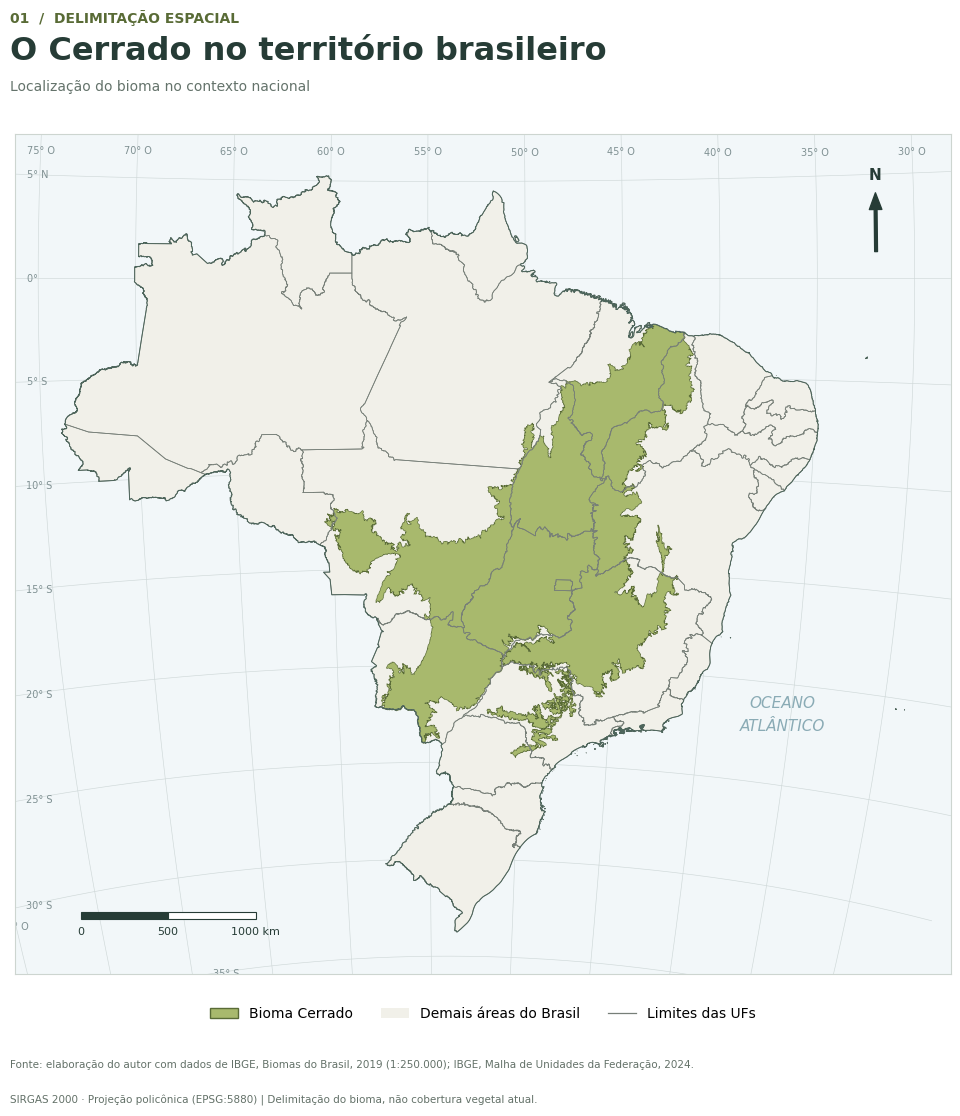

In [6]:
fig1=plt.figure(figsize=(11,11.5),facecolor="white")
cabecalho(fig1,"01","O Cerrado no território brasileiro","Localização do bioma no contexto nacional")
ax1=fig1.add_axes([.07,.13,.86,.73 if MOSTRAR_TITULO else .80])
base_mapa(ax1,limites(brasil_m,.055))
escala(ax1,1000)
ax1.text(.82,.29,"OCEANO\nATLÂNTICO",transform=ax1.transAxes,ha="center",fontsize=11,color="#8AABB5",style="italic",linespacing=1.6)
fig1.legend(handles=itens_legenda,loc="lower center",bbox_to_anchor=(.5,.078),ncol=3,frameon=False,fontsize=10)
rodape(fig1)
salvar(fig1,"mapa_01_brasil_cerrado")
plt.show()


## 7. Mapa 2 — Cerrado e limites das UFs
As siglas são posicionadas na maior porção do Cerrado em cada UF. O DF recebe uma chamada externa para facilitar a leitura. O quadro à direita apresenta os nomes completos. A seleção das UFs é calculada a partir dos polígonos, sem lista fixa.

Exportado: mapa_02_cerrado_ufs — PNG, PDF e SVG


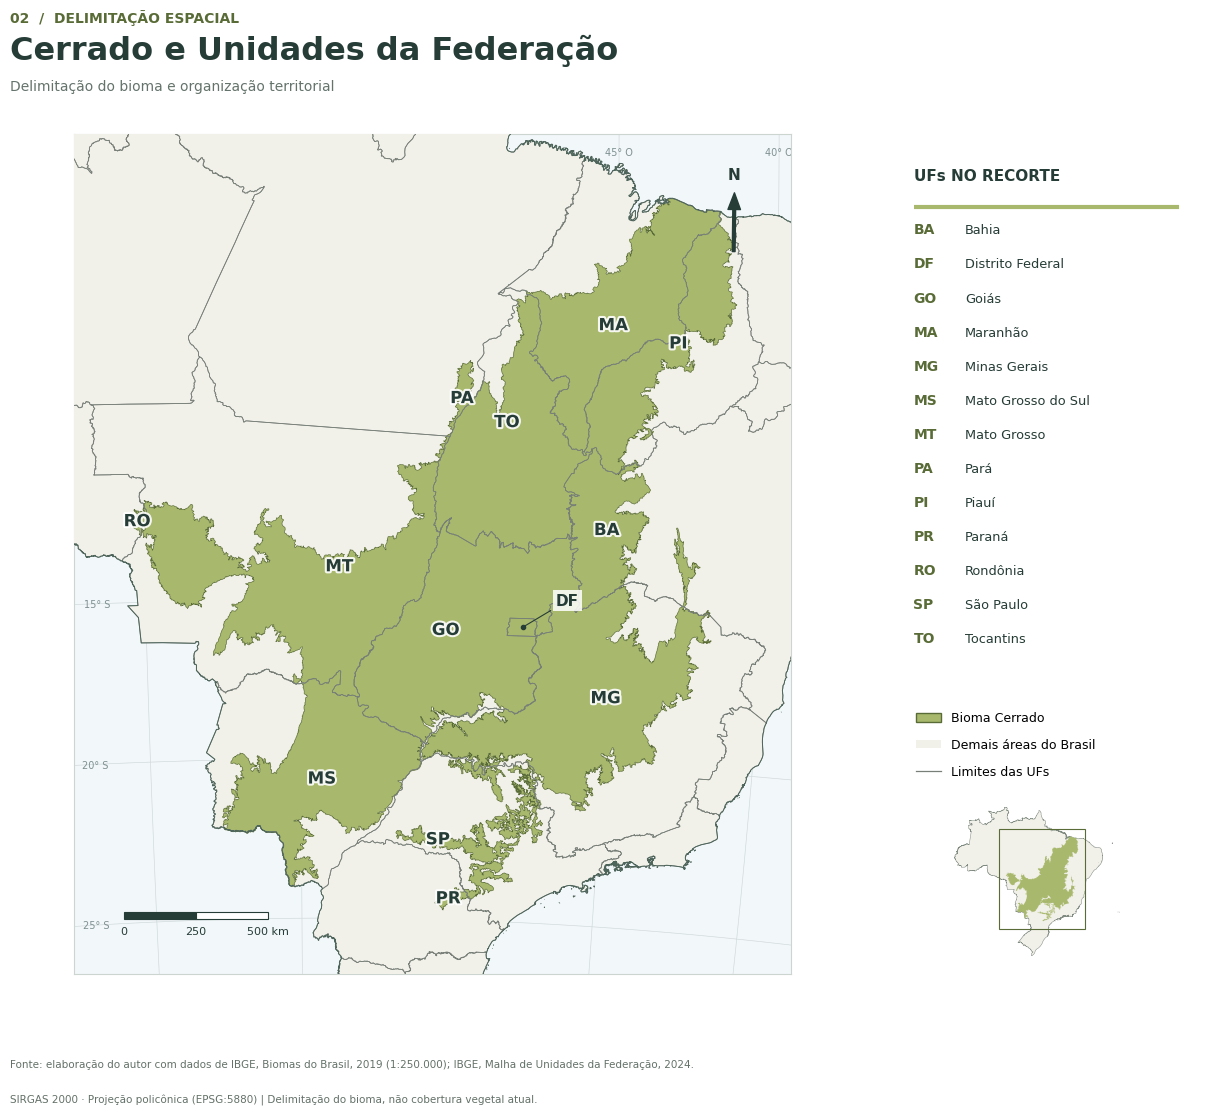

In [7]:
fig2=plt.figure(figsize=(13,11.5),facecolor="white")
cabecalho(fig2,"02","Cerrado e Unidades da Federação","Delimitação do bioma e organização territorial")
ax2=fig2.add_axes([.055,.13,.68,.73 if MOSTRAR_TITULO else .80])
extent2=limites(cerrado_m,.09)
base_mapa(ax2,extent2)
escala(ax2,500)
for _,r in intersecoes.iterrows():
    g=r.geometry
    if isinstance(g,MultiPolygon): g=max(g.geoms,key=lambda p:p.area)
    p=g.representative_point()
    if r.sigla=="DF":
        ax2.plot(p.x,p.y,"o",color=COR["texto"],ms=3,zorder=10)
        ax2.annotate("DF",xy=(p.x,p.y),xytext=(24,16),textcoords="offset points",fontsize=11,weight="bold",color=COR["texto"],arrowprops={"arrowstyle":"-","lw":.8,"color":COR["texto"]},bbox={"facecolor":"white","edgecolor":"none","alpha":.85,"pad":2},zorder=11)
    else:
        ax2.text(p.x,p.y,r.sigla,ha="center",va="center",fontsize=12,weight="bold",color=COR["texto"],path_effects=[pe.withStroke(linewidth=3,foreground="white",alpha=.9)],zorder=9)
quadro=fig2.add_axes([.765,.30,.22,.52]); quadro.axis("off")
quadro.text(0,1,"UFs NO RECORTE",fontsize=11,weight="bold",color=COR["texto"],transform=quadro.transAxes)
quadro.plot([0,.92],[.955,.955],color=COR["cerrado"],lw=3,transform=quadro.transAxes)
passo=min(.057,.85/max(1,len(tabela_ufs)))
for i,(_,r) in enumerate(tabela_ufs.iterrows()):
    y=.91-i*passo
    quadro.text(0,y,r.sigla,fontsize=10,weight="bold",color=COR["borda"],transform=quadro.transAxes)
    quadro.text(.18,y,r.nome,fontsize=9.3,color=COR["texto"],transform=quadro.transAxes)
quadro.legend(handles=itens_legenda,loc="upper left",bbox_to_anchor=(-.03,.13),frameon=False,fontsize=9,labelspacing=1.1)
# Mapa localizador, sem detalhes administrativos redundantes.
localizador=fig2.add_axes([.79,.135,.14,.15])
localizador.set_aspect("equal")
brasil_d.plot(ax=localizador,color=COR["terra"],edgecolor="#7F8A80",lw=.35)
cerrado_d.plot(ax=localizador,color=COR["cerrado"],edgecolor="none")
x0,x1,y0,y1=extent2
localizador.add_patch(Rectangle((x0,y0),x1-x0,y1-y0,fill=False,edgecolor=COR["borda"],lw=.8))
localizador.axis("off")
rodape(fig2)
salvar(fig2,"mapa_02_cerrado_ufs")
plt.show()


## 8. Registrar fontes e baixar os resultados
O ZIP inclui as seis imagens, a tabela de UFs, sugestões de legendas e um registro com fontes, edições, hashes dos arquivos e versões das bibliotecas. As bases geográficas não são incluídas no ZIP de figuras.

**No Word:** insira o PNG, mantenha a proporção e use **Referências → Inserir legenda** para numerar automaticamente. O PDF e o SVG preservam a qualidade vetorial. A área verde representa a delimitação do bioma, não remanescentes de vegetação nativa nem as glebas financiadas.

In [8]:
import shutil

def sha256(p):
    h=hashlib.sha256()
    with p.open("rb") as f:
        for bloco in iter(lambda:f.read(1024*1024),b""): h.update(bloco)
    return h.hexdigest()
metadados={
    "gerado_em_utc":datetime.now(timezone.utc).isoformat(),
    "fonte_biomas":fonte_biomas,"fonte_ufs":fonte_ufs,
    "url_biomas":None if ARQUIVO_BIOMAS else URLS_BIOMAS[EDICAO_BIOMAS],
    "url_ufs":None if ARQUIVO_UFS else URL_UFS,
    "arquivo_biomas":str(p_biomas),"arquivo_ufs":str(p_ufs),
    "sha256_biomas":sha256(p_biomas),"sha256_ufs":sha256(p_ufs),
    "crs_mapa":"EPSG:5880","dpi_png":DPI,"tolerancia_desenho_m":350,
    "criterio_ufs":"Interseção poligonal de área positiva, sem simplificação ou limiar mínimo de área.",
    "ufs":tabela_ufs.sigla.tolist(),
    "versoes":{"python":platform.python_version(),"geopandas":gpd.__version__,"matplotlib":matplotlib.__version__},
    "nota":"O mapa deve usar a mesma delimitação adotada na análise da dissertação. O destaque não representa cobertura vegetal atual."
}
(SAIDA/"fontes_e_metadados.json").write_text(json.dumps(metadados,ensure_ascii=False,indent=2),encoding="utf-8")
legendas=f"""Figura X – Localização do bioma Cerrado no território brasileiro.
Figura Y – Delimitação do bioma Cerrado e limites das Unidades da Federação abrangidas.
Fonte: elaborado pelo autor com dados de {fonte_biomas}; {fonte_ufs}.
Nota: representação da delimitação do bioma, e não da cobertura vegetal atual.

Substitua X e Y usando a numeração automática do Word.
Antes de inserir, confira se a edição dos biomas corresponde à usada na pesquisa.
"""
(SAIDA/"legendas_para_dissertacao.txt").write_text(legendas,encoding="utf-8")
zip_final=shutil.make_archive(str(RAIZ/"Mapas_Cerrado_Dissertacao"),"zip",SAIDA)
print("Concluído:",zip_final)
for p in sorted(SAIDA.iterdir()): print(f"  {p.name}: {p.stat().st_size/1024:.0f} KB")
if BAIXAR_ZIP_NO_COLAB:
    try:
        from google.colab import files
    except ImportError:
        print("Fora do Colab: os arquivos estão disponíveis na pasta indicada acima.")
    else:
        files.download(zip_final)


Concluído: /content/mapas_cerrado/Mapas_Cerrado_Dissertacao.zip
  fontes_e_metadados.json: 1 KB
  legendas_para_dissertacao.txt: 1 KB
  mapa_01_brasil_cerrado.pdf: 1038 KB
  mapa_01_brasil_cerrado.png: 2149 KB
  mapa_01_brasil_cerrado.svg: 2941 KB
  mapa_02_cerrado_ufs.pdf: 1439 KB
  mapa_02_cerrado_ufs.png: 2572 KB
  mapa_02_cerrado_ufs.svg: 4120 KB
  ufs_intersectadas_pelo_cerrado.csv: 0 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>